# Air Quality Clustering with K-Means

## Objective
Group daily observations into air-quality profiles using pollutant concentrations, without using the provided AQI or AQI_Bucket labels. This is an **unsupervised learning** task: clusters are discovered from pollutant patterns rather than trained against known categories.

**Dataset:** `city_day.csv` (India city-wise daily air-quality data). Place this notebook and the CSV in the same folder, or update `DATA_PATH` below.

In [14]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
from sklearn.decomposition import PCA

RANDOM_STATE = 42
DATA_PATH = "city_day.csv"  # Change this if your CSV has a different filename/path

df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head())
print("\nMissing values in the dataset (top 10):")
display(df.isna().sum().sort_values(ascending=False).head(10).to_frame("missing_count"))

Dataset shape: (29531, 16)


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN



Missing values in the dataset (top 10):


,missing_count
Xylene,18109
PM10,11140
NH3,10328
Toluene,8041
Benzene,5623
AQI,4681
AQI_Bucket,4681
PM2.5,4598
NOx,4185
O3,4022


## 1. Prepare the clustering dataset

### Feature selection
Use measured pollutant concentrations: `PM2.5`, `PM10`, `NO`, `NO2`, `NOx`, `NH3`, `CO`, `SO2`, `O3`, `Benzene`, and `Toluene`.

- **Exclude `AQI` and `AQI_Bucket`** because they are outcome/label-like fields. Including them would leak an existing air-quality summary into clusters that should be based on pollutants alone.
- **Exclude `City` and `Date`** from K-Means because they are identifiers/time metadata, not pollutant concentration measurements. They can be retained for interpreting clusters later.
- **Exclude `Xylene`** because more than half of its values are missing in this dataset; median imputation of such a high-missingness feature could introduce substantial noise.
- Impute remaining missing pollutant readings with each feature's median, then standardize features. Scaling is important because pollutants have very different units and numeric ranges; without scaling, high-magnitude features can dominate Euclidean distance.

In [15]:
pollutant_candidates = [
    "PM2.5", "PM10", "NO", "NO2", "NOx", "NH3",
    "CO", "SO2", "O3", "Benzene", "Toluene", "Xylene"
]
available = [c for c in pollutant_candidates if c in df.columns]
missing_rate = df[available].isna().mean()
print("Missing fraction by pollutant:")
display(missing_rate.sort_values(ascending=False).to_frame("missing_fraction"))

# Drop features with >50% missingness; exclude AQI labels and all non-pollutant columns.
features = [c for c in available if missing_rate[c] <= 0.50]
print("Selected clustering features:", features)
print("Excluded due to >50% missing:", [c for c in available if c not in features])

X_raw = df[features].apply(pd.to_numeric, errors="coerce")
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X_raw)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

print("Rows used:", X_scaled.shape[0])
print("Number of features:", X_scaled.shape[1])
print("Missing values after imputation:", int(np.isnan(X_imputed).sum()))
print("Scaled feature means (approx. 0):", np.round(X_scaled.mean(axis=0), 3))
print("Scaled feature std devs (approx. 1):", np.round(X_scaled.std(axis=0), 3))

Missing fraction by pollutant:


,missing_fraction
Xylene,0.613220
PM10,0.377231
NH3,0.349734
Toluene,0.272290
Benzene,0.190410
PM2.5,0.155701
NOx,0.141715
O3,0.136196
SO2,0.130507
NO2,0.121398


Selected clustering features: ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene']
Excluded due to >50% missing: ['Xylene']
Rows used: 29531
Number of features: 11
Missing values after imputation: 0
Scaled feature means (approx. 0): [-0. -0.  0.  0.  0. -0.  0. -0.  0. -0.  0.]
Scaled feature std devs (approx. 1): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## 2. Choose the number of clusters with the elbow method

Fit K-Means for a range of `k` values and plot **inertia** (within-cluster sum of squared distances). Inertia always decreases as `k` increases, so look for the point where the improvement begins to flatten rather than automatically choosing the lowest value.

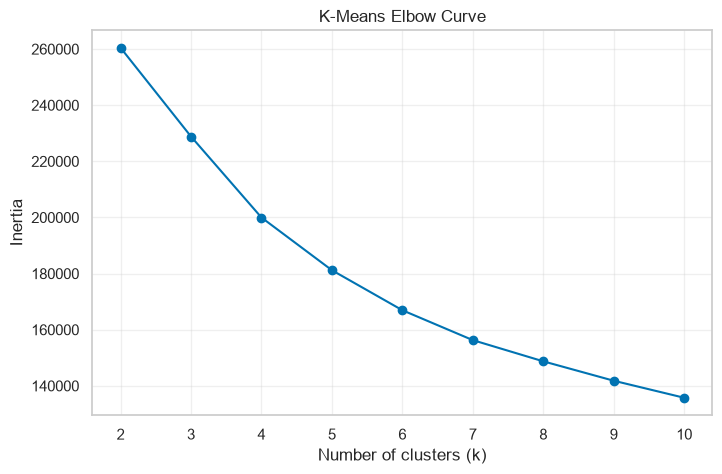

,k,inertia
0,2,260447.785197
1,3,228818.730508
2,4,199962.141419
3,5,181183.961707
4,6,166929.748717
5,7,156276.278323
6,8,148724.617976
7,9,141811.234247
8,10,135744.308661


In [16]:
k_values = range(2, 11)
inertias = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.xticks(list(k_values))
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("K-Means Elbow Curve")
plt.grid(True, alpha=0.3)
plt.show()

pd.DataFrame({"k": list(k_values), "inertia": inertias})

### Elbow choice

Inspect the elbow plot above and choose a `k` where the curve starts to flatten. The cell below computes silhouette scores for the same candidates as a secondary diagnostic, then selects the `k` with the highest silhouette score as a reproducible default. **Check this selected value against the elbow curve**: if the elbow clearly suggests a simpler solution, change `CHOSEN_K` manually and rerun the remaining cells. Silhouette is a supporting metric, not a replacement for interpreting the elbow and the domain.

In [17]:
# Secondary diagnostic to make the choice reproducible; sample for speed on larger datasets.
rng = np.random.RandomState(RANDOM_STATE)
sample_size = min(5000, X_scaled.shape[0])
sample_idx = rng.choice(X_scaled.shape[0], size=sample_size, replace=False)
X_sample = X_scaled[sample_idx]

diagnostics = []
for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels_sample = model.fit_predict(X_sample)
    diagnostics.append({
        "k": k,
        "sample_silhouette": silhouette_score(X_sample, labels_sample)
    })

diagnostics_df = pd.DataFrame(diagnostics)
display(diagnostics_df)
CHOSEN_K = int(diagnostics_df.loc[diagnostics_df["sample_silhouette"].idxmax(), "k"])
print("Default chosen k from sampled silhouette diagnostic:", CHOSEN_K)
print("Confirm this is reasonable against the elbow curve before finalizing.")

,k,sample_silhouette
0,2,0.523726
1,3,0.497089
2,4,0.292124
3,5,0.302532
4,6,0.267934
5,7,0.253844
6,8,0.260339
7,9,0.263310
8,10,0.263733


Default chosen k from sampled silhouette diagnostic: 2
Confirm this is reasonable against the elbow curve before finalizing.


## 3. Fit the final K-Means model

Fit K-Means to all prepared rows using the selected `k`, then attach cluster IDs to a copy of the original dataset for interpretation. Cluster IDs (`0`, `1`, …) are arbitrary names, not rankings.

In [18]:
kmeans = KMeans(n_clusters=CHOSEN_K, random_state=RANDOM_STATE, n_init=10)
cluster_labels = kmeans.fit_predict(X_scaled)

clustered_df = df.copy()
clustered_df["Cluster"] = cluster_labels

print("Final model:", kmeans)
print("\nRows per cluster:")
display(clustered_df["Cluster"].value_counts().sort_index().to_frame("row_count"))
print("\nMean pollutant concentrations by cluster (original units):")
display(clustered_df.groupby("Cluster")[features].mean().round(2))
print("\nExample assigned rows:")
display(clustered_df[["City", "Date"] + features + ["Cluster"]].head(10))

Final model: KMeans(n_clusters=2, n_init=10, random_state=42)

Rows per cluster:


,row_count
Cluster,
0,4086
1,25445



Mean pollutant concentrations by cluster (original units):


,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene
Cluster,,,,,,,,,,,
0,141.33,249.93,50.42,64.21,79.41,37.67,8.19,30.92,44.03,9.07,25.04
1,53.32,95.74,11.47,21.99,23.49,21.49,1.22,11.48,32.74,2.15,5.33



Example assigned rows:


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Cluster
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,1
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,1
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,1
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,1
5,Ahmedabad,2015-01-06,NaN,NaN,45.41,38.48,81.50,NaN,45.41,45.76,46.51,5.42,10.83,0
6,Ahmedabad,2015-01-07,NaN,NaN,112.16,40.62,130.77,NaN,112.16,32.28,33.47,0.00,0.00,0
7,Ahmedabad,2015-01-08,NaN,NaN,80.87,36.74,96.75,NaN,80.87,38.54,31.89,0.00,0.00,0
8,Ahmedabad,2015-01-09,NaN,NaN,29.16,31.00,48.00,NaN,29.16,58.68,25.75,0.00,0.00,0
9,Ahmedabad,2015-01-10,NaN,NaN,NaN,7.04,0.00,NaN,NaN,8.29,4.55,0.00,0.00,1


## 4. Evaluate K-Means clustering

- **Silhouette score:** ranges from −1 to 1; higher generally means better-separated, more cohesive clusters.
- **Davies–Bouldin index:** lower is generally better; it compares within-cluster spread with separation between clusters.
- **Calinski–Harabasz score:** higher generally indicates dense, well-separated clusters.

These are internal clustering metrics, not accuracy scores. They do not prove that the clusters correspond to official AQI categories.

In [19]:
sil = silhouette_score(X_scaled, cluster_labels, sample_size=min(5000, len(cluster_labels)), random_state=RANDOM_STATE)
dbi = davies_bouldin_score(X_scaled, cluster_labels)
chi = calinski_harabasz_score(X_scaled, cluster_labels)

metrics_df = pd.DataFrame({
    "Metric": ["Silhouette Score", "Davies-Bouldin Index", "Calinski-Harabasz Score"],
    "Value": [sil, dbi, chi],
    "Preferred direction": ["Higher (max 1)", "Lower", "Higher"]
})
display(metrics_df)
print("Interpretation: compare these values across plausible k values; no single metric should be used alone.")

,Metric,Value,Preferred direction
0,Silhouette Score,0.512671,Higher (max 1)
1,Davies-Bouldin Index,1.542037,Lower
2,Calinski-Harabasz Score,7300.772481,Higher


Interpretation: compare these values across plausible k values; no single metric should be used alone.


## 5. PCA 2D visualization

PCA reduces the standardized pollutant features to two dimensions for visualization. Each point is one daily observation, colored by its K-Means cluster. PCA is used **only for plotting**; K-Means was fitted on the full scaled feature space.

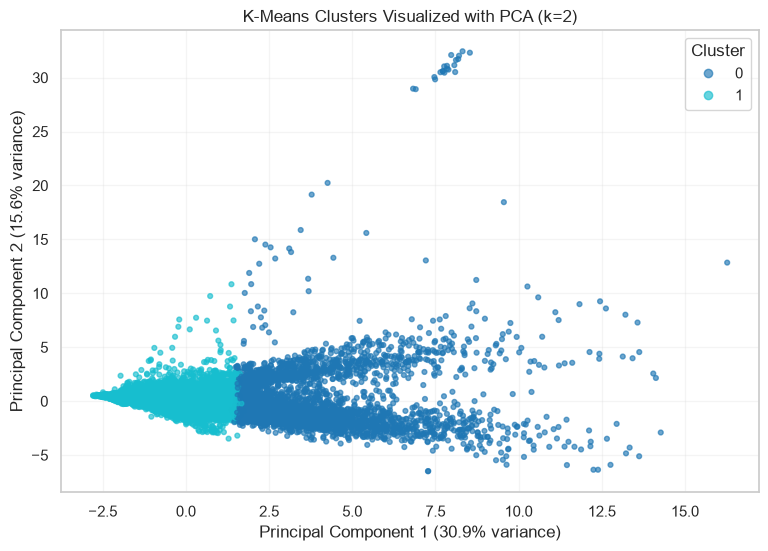

Total variance explained by 2 PCA components: 46.50%


In [20]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=cluster_labels, cmap="tab10", s=12, alpha=0.65
)
plt.xlabel(f"Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.title(f"K-Means Clusters Visualized with PCA (k={CHOSEN_K})")
plt.legend(*scatter.legend_elements(), title="Cluster", loc="best")
plt.grid(True, alpha=0.2)
plt.show()

print("Total variance explained by 2 PCA components:",
      f"{pca.explained_variance_ratio_.sum()*100:.2f}%")

## 6. Interpretation and verification

Use the cluster means above to describe each cluster by its pollutant profile. For example, a cluster with higher average PM2.5/PM10 may represent a particulate-heavy profile, while a cluster with higher NO₂/NOx/CO may reflect a different pollution mixture. **Do not assign labels such as “Good” or “Hazardous” based only on cluster ID**; inspect the actual means and compare with official thresholds only if you add a separate, clearly documented analysis.

### Verification checklist
- [x] `AQI` and `AQI_Bucket` excluded from clustering features.
- [x] `City` and `Date` excluded from numerical feature matrix.
- [x] High-missingness `Xylene` excluded; remaining missing values median-imputed.
- [x] Features standardized before Euclidean-distance-based K-Means.
- [x] Elbow curve generated for k = 2 to 10.
- [x] Final cluster labels created.
- [x] Silhouette, Davies–Bouldin, and Calinski–Harabasz metrics calculated.
- [x] PCA 2D cluster plot generated.

**Caveat:** this dataset contains daily records from multiple cities. Clusters may partly reflect city-specific pollutant patterns as well as pollution severity. Treat them as pollutant-profile groups, not automatically as AQI categories.

# Part 2: Agglomerative Hierarchical Clustering
**Member:** Adithya

This part reuses everything above (`df`, `features`, `X_imputed`, `X_scaled`, `CHOSEN_K`, the fitted `kmeans`) so both algorithms are compared on identical data. `AQI` and `AQI_Bucket` are never used while fitting; `AQI_Bucket` is used only at the end for interpretation.

In [21]:
import seaborn as sns
from sklearn.cluster import AgglomerativeClustering
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet
from scipy.spatial.distance import pdist

sns.set_theme(style="whitegrid", palette="colorblind")
PALETTE = sns.color_palette("colorblind")
K = CHOSEN_K          # same k as the K-Means section

## 7. Hierarchical Clustering: Working Sample

Agglomerative clustering compares every pair of points. For all 29,531 rows that is about 436 million distances (several GB of memory), which is impractical. We therefore cluster a **random sample of 5,000 rows** (`random_state = 42`), the same size and seed as the K-Means diagnostic sample, so both algorithms can be scored on exactly the same rows.

In [22]:
N_SAMPLE = 5000
rng_h = np.random.RandomState(RANDOM_STATE)
hc_idx = rng_h.choice(X_scaled.shape[0], size=N_SAMPLE, replace=False)

X_hc      = X_scaled[hc_idx]                                   # scaled, used for clustering
X_hc_orig = pd.DataFrame(X_imputed[hc_idx], columns=features)  # original units, for profiling
df_hc     = df.iloc[hc_idx].reset_index(drop=True)

print("Sample shape:", X_hc.shape)
print("Pairwise distances in sample   :", f"{N_SAMPLE*(N_SAMPLE-1)//2:,}")
print("Pairwise distances in full data:", f"{len(X_scaled)*(len(X_scaled)-1)//2:,}")

Sample shape: (5000, 11)
Pairwise distances in sample   : 12,497,500
Pairwise distances in full data: 436,025,215


## 8. Dendrogram (Ward linkage)

A dendrogram shows the order in which clusters merge and the distance at which each merge happens. Tall vertical lines mean two very different groups were joined. A horizontal cut gives a flat clustering. With 5,000 leaves the full tree is unreadable, so only the last 30 merges are drawn; the number in brackets is how many points a branch holds.

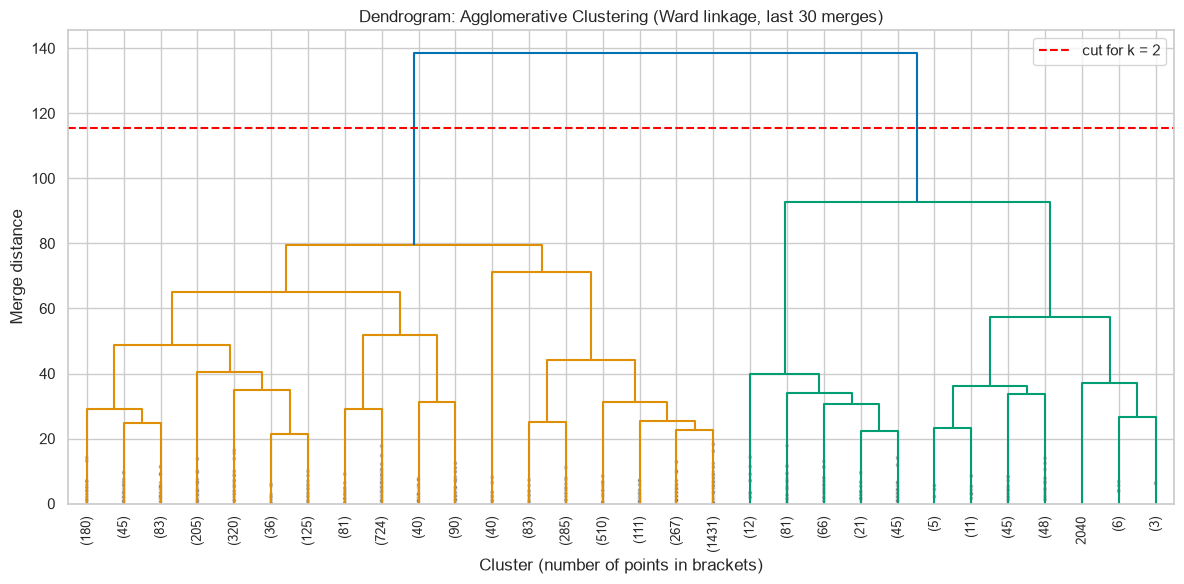

Last merge heights (largest first): [138.5  92.6  79.6  71.1  65.1  57.4]


In [23]:
Z_ward = linkage(X_hc, method="ward")

# a cut giving K clusters sits between the (K-1)th-last and Kth-last merge heights
cut_height = (Z_ward[-(K - 1), 2] + Z_ward[-K, 2]) / 2

plt.figure(figsize=(12, 6))
dendrogram(Z_ward, truncate_mode="lastp", p=30, leaf_rotation=90,
           leaf_font_size=9, show_contracted=True, color_threshold=cut_height)
plt.axhline(cut_height, color="red", linestyle="--", label=f"cut for k = {K}")
plt.title("Dendrogram: Agglomerative Clustering (Ward linkage, last 30 merges)")
plt.xlabel("Cluster (number of points in brackets)")
plt.ylabel("Merge distance")
plt.legend()
plt.tight_layout()
plt.show()

print("Last merge heights (largest first):", np.round(Z_ward[-6:, 2][::-1], 1))

### Observation: Dendrogram

The largest jump among the final merge heights is from **92.6 to 138.5**, suggesting that the final merge combines two relatively distinct groups; this supports considering **k = 2**. At the selected cut, however, the groups are very unequal: **344 observations** in the smaller cluster and **4,656** in the larger one. The dendrogram therefore suggests a broad split, not two equally sized groups.

## 9. Choosing k for Ward Linkage

Hierarchical clustering has no elbow plot, so the dendrogram and the validity indices guide the choice. We score k = 2 to 8 with Ward linkage on the sample.

,Silhouette (higher),Davies-Bouldin (lower),Calinski-Harabasz (higher),smallest cluster
k,,,,
2,0.596,1.422,1161.163,344
3,0.574,1.225,937.248,119
4,0.190,1.811,838.839,119
5,0.200,1.558,780.600,40
6,0.195,1.605,741.972,40
7,0.197,1.517,704.806,10
8,0.169,1.481,671.300,10


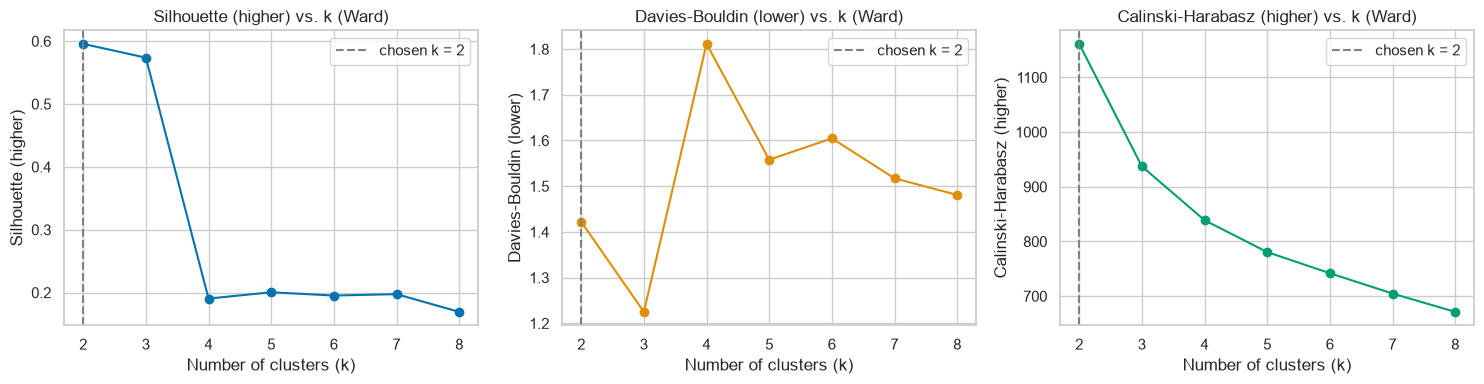

In [24]:
def cluster_metrics(X, labels):
    return {"Silhouette (higher)": silhouette_score(X, labels),
            "Davies-Bouldin (lower)": davies_bouldin_score(X, labels),
            "Calinski-Harabasz (higher)": calinski_harabasz_score(X, labels)}

rows = []
for k in range(2, 9):
    lab = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X_hc)
    rows.append({"k": k, **cluster_metrics(X_hc, lab), "smallest cluster": np.bincount(lab).min()})

ward_k_table = pd.DataFrame(rows).set_index("k")
display(ward_k_table.round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, color in zip(axes, ["Silhouette (higher)", "Davies-Bouldin (lower)", "Calinski-Harabasz (higher)"], PALETTE):
    ax.plot(ward_k_table.index, ward_k_table[col], "o-", color=color)
    ax.axvline(K, color="grey", linestyle="--", label=f"chosen k = {K}")
    ax.set_title(f"{col} vs. k (Ward)")
    ax.set_xlabel("Number of clusters (k)")
    ax.set_ylabel(col)
    ax.legend()
plt.tight_layout()
plt.show()

### Observation: Choosing k

For Ward linkage, **k = 2** has the highest Silhouette score (**0.596**) and Calinski–Harabasz score (**1161.163**). The lowest Davies–Bouldin index occurs at **k = 3** (**1.225**, compared with **1.422** at k = 2), so the indices do not all agree. We retain **k = 2** because it performs best on two of the three indices and matches the K-Means choice, allowing a like-for-like comparison. This is a practical choice rather than proof that two clusters are the only natural solution.

## 10. Comparing Linkage Strategies

| Linkage | Distance between two clusters |
|---|---|
| **ward** | increase in total within-cluster variance if they are merged |
| **average** | mean distance over all point pairs |
| **complete** | distance between the two *farthest* points |
| **single** | distance between the two *closest* points |

All four are fitted with k = 2. The **cophenetic correlation** measures how faithfully the dendrogram preserves the original pairwise distances (closer to 1 is better).

In [25]:
pair_dist = pdist(X_hc)
rows, linkage_labels = [], {}

for method in ["ward", "average", "complete", "single"]:
    Z = linkage(X_hc, method=method)
    coph = cophenet(Z, pair_dist)[0]
    lab = AgglomerativeClustering(n_clusters=K, linkage=method).fit_predict(X_hc)
    linkage_labels[method] = lab
    rows.append({"Linkage": method, **cluster_metrics(X_hc, lab),
                 "Cophenetic corr.": coph, "Cluster sizes": np.bincount(lab).tolist()})

linkage_table = pd.DataFrame(rows).set_index("Linkage")
display(linkage_table.round(3))

,Silhouette (higher),Davies-Bouldin (lower),Calinski-Harabasz (higher),Cophenetic corr.,Cluster sizes
Linkage,,,,,
ward,0.596,1.422,1161.163,0.658,"[344, 4656]"
average,0.883,0.474,176.951,0.912,"[2, 4998]"
complete,0.836,0.734,164.630,0.843,"[4, 4996]"
single,0.905,0.064,146.286,0.842,"[4999, 1]"


### Observation: Linkage Comparison

Check the **Cluster sizes** column before trusting the scores. Average, complete and single linkage each put only a handful of points in one cluster and everything else in the other: they have found a few extreme outliers rather than a real grouping. Their Silhouette and Davies-Bouldin values look excellent only because one huge cluster dominates, so high scores alone can mislead.

**Cophenetic correlation caveat:** average linkage has the highest value, yet it still isolates just 2 points. Cophenetic correlation measures how faithfully the *tree* preserves pairwise distances; it does not say whether cutting the tree gives useful clusters. Ward's merge heights are also on a different scale (variance increase, not raw distance), so its value is not directly comparable.

Ward gives the most useful split among these four choices, although it is still imbalanced (**344 vs. 4,656** observations). Average, complete and single linkage produce degenerate splits with only **2, 4 and 1** observations in their small clusters, respectively. Their high Silhouette scores are therefore misleading for this task. Ward is selected because it avoids isolating only a few points and gives a more interpretable division of the sample; its lower cophenetic correlation does not outweigh the poor cluster sizes produced by the other methods.

## 11. Final Model: Agglomerative Clustering (Ward, k = 2)

In [26]:
hier = AgglomerativeClustering(n_clusters=K, linkage="ward")
labels_h = hier.fit_predict(X_hc)

print("Rows per cluster (sample):")
display(pd.Series(labels_h).value_counts().sort_index().to_frame("row_count"))

display(pd.DataFrame(cluster_metrics(X_hc, labels_h), index=["Agglomerative (Ward, k=2)"]).round(3))

Rows per cluster (sample):


,row_count
0,344
1,4656


,Silhouette (higher),Davies-Bouldin (lower),Calinski-Harabasz (higher)
"Agglomerative (Ward, k=2)",0.596,1.422,1161.163


### Cluster Profiles

Mean pollutant concentration in each cluster, in the **original** units.

,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,rows
0,147.42,236.56,63.77,76.30,92.49,31.18,12.81,37.87,43.61,11.03,31.18,344
1,59.14,101.17,12.87,24.02,26.00,20.36,1.29,12.22,33.46,1.85,5.07,4656


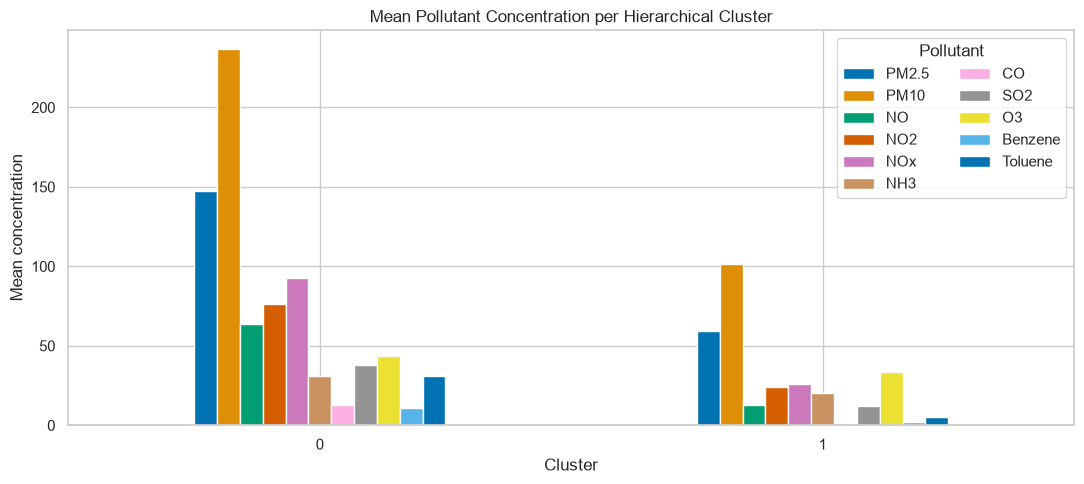

In [27]:
profile = X_hc_orig.groupby(labels_h).mean().round(2)
profile["rows"] = np.bincount(labels_h)
display(profile)

profile[features].plot(kind="bar", figsize=(11, 5))
plt.title("Mean Pollutant Concentration per Hierarchical Cluster")
plt.xlabel("Cluster")
plt.ylabel("Mean concentration")
plt.xticks(rotation=0)
plt.legend(title="Pollutant", ncol=2)
plt.tight_layout()
plt.show()

### Observation: Final Model and Profiles

The Ward model has a Silhouette score of **0.596**, a Davies–Bouldin index of **1.422**, and a Calinski–Harabasz score of **1161.163**. Together these indicate some separation between the two groups, but the metrics do not guarantee that the clusters are perfect or equally sized. **Cluster 0** contains 344 observations and has much higher average PM2.5 (**147.42**), PM10 (**236.56**), NO (**63.77**), NO₂ (**76.30**), NOx (**92.49**) and CO (**12.81**) than Cluster 1. It represents a smaller, more pollutant-heavy profile. **Cluster 1** contains 4,656 observations and has lower average concentrations for these pollutants, representing the larger, comparatively lower-pollution profile. These are pollutant profiles, not official AQI labels.

## 12. PCA Visualisation (2 Components)

PCA is fitted on the scaled sample. The K-Means model from the earlier section (fitted on **all** rows) is used to label the same 5,000 rows, so both plots show identical points.

Variance explained by 2 components: 48.5 %


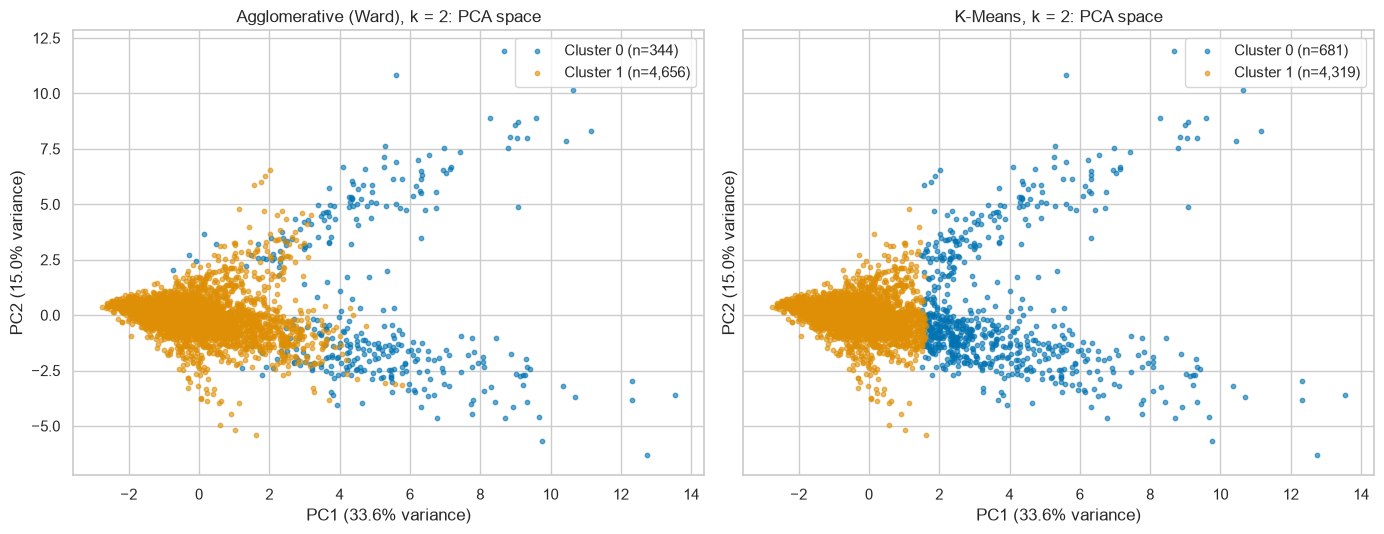

In [28]:
labels_k = kmeans.predict(X_hc)

pca_hc = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca_hc = pca_hc.fit_transform(X_hc)
print("Variance explained by 2 components:", round(pca_hc.explained_variance_ratio_.sum() * 100, 1), "%")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)
for ax, labs, title in [(axes[0], labels_h, "Agglomerative (Ward)"), (axes[1], labels_k, "K-Means")]:
    for c in range(K):
        m = labs == c
        ax.scatter(X_pca_hc[m, 0], X_pca_hc[m, 1], s=10, alpha=0.6, color=PALETTE[c], label=f"Cluster {c} (n={m.sum():,})")
    ax.set_title(f"{title}, k = {K}: PCA space")
    ax.set_xlabel(f"PC1 ({pca_hc.explained_variance_ratio_[0]:.1%} variance)")
    ax.set_ylabel(f"PC2 ({pca_hc.explained_variance_ratio_[1]:.1%} variance)")
    ax.legend()
plt.tight_layout()
plt.show()

### Observation: PCA

The first two principal components explain **48.5%** of the variance in the 11 standardized pollutant features. The 2D plot therefore shows less than half of the total variation, so apparent overlap or separation may not fully reflect the original 11-dimensional space. The small Ward cluster contains **344** observations and the larger cluster **4,656**; K-Means assigns **681** and **4,319** observations on the same sample. The two algorithms broadly divide the sample into a smaller and a larger group, but their boundaries and assignments are not identical. PCA is useful for visual inspection, not as a standalone test of cluster quality.

## 13. t-SNE Visualisation

t-SNE is non-linear: it keeps **neighbourhoods** (close in 11-D stays close in 2-D) but not global distances, so cluster sizes and gaps in the picture should not be over-interpreted. One embedding is computed and coloured twice so the algorithms are compared on identical coordinates.

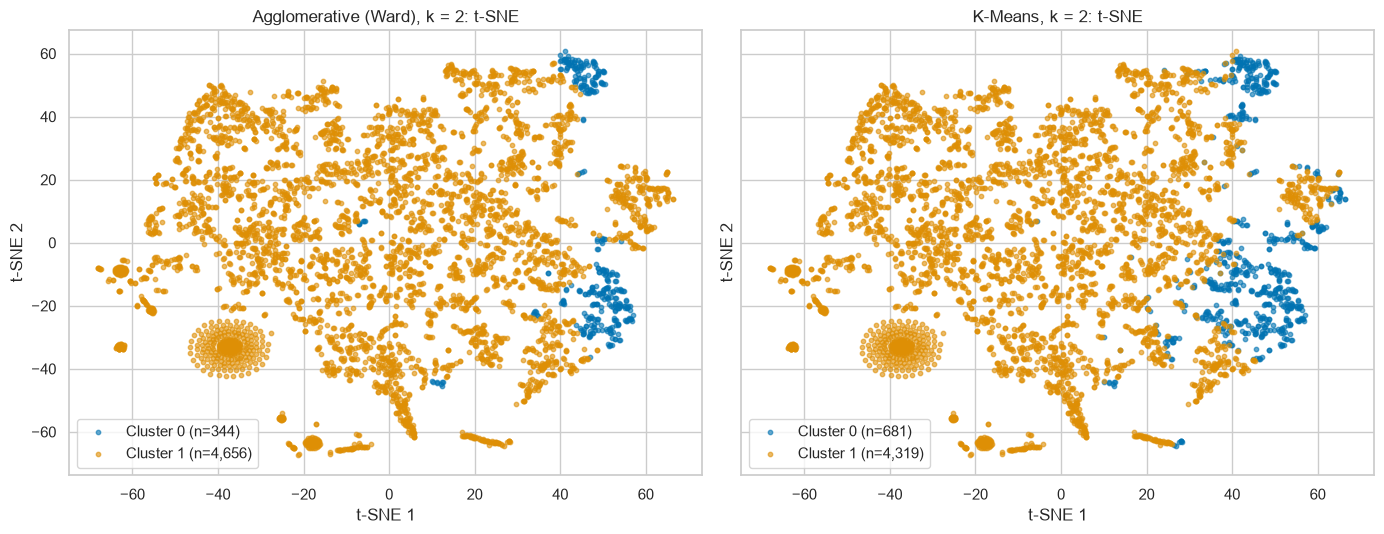

In [29]:
tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=RANDOM_STATE)
X_tsne = tsne.fit_transform(X_hc)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)
for ax, labs, title in [(axes[0], labels_h, "Agglomerative (Ward)"), (axes[1], labels_k, "K-Means")]:
    for c in range(K):
        m = labs == c
        ax.scatter(X_tsne[m, 0], X_tsne[m, 1], s=10, alpha=0.6, color=PALETTE[c], label=f"Cluster {c} (n={m.sum():,})")
    ax.set_title(f"{title}, k = {K}: t-SNE")
    ax.set_xlabel("t-SNE 1")
    ax.set_ylabel("t-SNE 2")
    ax.legend()
plt.tight_layout()
plt.show()

### Observation: t-SNE

The t-SNE plots display the same 5,000 observations in a shared 2D embedding, coloured once by Ward labels and once by K-Means labels. The algorithms disagree on some assignments: their Adjusted Rand Index is **0.565**, indicating partial rather than exact agreement. Use the plot to inspect whether local neighbourhoods form visible regions, but do not interpret the apparent area or spacing as true cluster size or global distance. t-SNE is designed to preserve local neighbourhood structure and can distort global geometry; the cluster counts from the original labels are the reliable sizes.

## 14. K-Means vs. Hierarchical: Comparison Table

Both algorithms are scored on the **same 5,000 rows**. Calinski-Harabasz grows with the number of rows, so these values cannot be compared with the full-data value in the K-Means section.

In [30]:
comparison = pd.DataFrame(
    [cluster_metrics(X_hc, labels_k), cluster_metrics(X_hc, labels_h)],
    index=["K-Means (k=2)", "Agglomerative Ward (k=2)"]
)
comparison["Cluster sizes"] = [np.bincount(labels_k).tolist(), np.bincount(labels_h).tolist()]
display(comparison.round(3))

print("Agreement between the two clusterings (Adjusted Rand Index):",
      round(adjusted_rand_score(labels_k, labels_h), 3))

,Silhouette (higher),Davies-Bouldin (lower),Calinski-Harabasz (higher),Cluster sizes
K-Means (k=2),0.513,1.485,1392.338,"[681, 4319]"
Agglomerative Ward (k=2),0.596,1.422,1161.163,"[344, 4656]"


Agreement between the two clusterings (Adjusted Rand Index): 0.565


### Observation: Comparison

On the shared 5,000-row sample, **Ward** has the higher Silhouette score (**0.596 vs. 0.513**) and lower Davies–Bouldin index (**1.422 vs. 1.485**). **K-Means** has the higher Calinski–Harabasz score (**1392.338 vs. 1161.163**). The Adjusted Rand Index is **0.565**, so the methods show moderate agreement but do not produce identical assignments. K-Means is faster and was fitted to all 29,531 rows, while hierarchical clustering provides a dendrogram but is limited here to a 5,000-row sample because of its computational cost. The metric results are mixed, so neither method wins on every measure.

## 15. Post-hoc Validation against AQI Buckets

Only **after** clustering do we compare with the known `AQI_Bucket`, purely for interpretation. It was never used in fitting.

AQI_Bucket,Good,Satisfactory,Moderate,Poor,Very Poor,Severe
Hierarchical cluster,,,,,,
0,2,4,18,44,106,160
1,204,1359,1527,417,295,78


Adjusted Rand Index vs. AQI_Bucket: 0.084


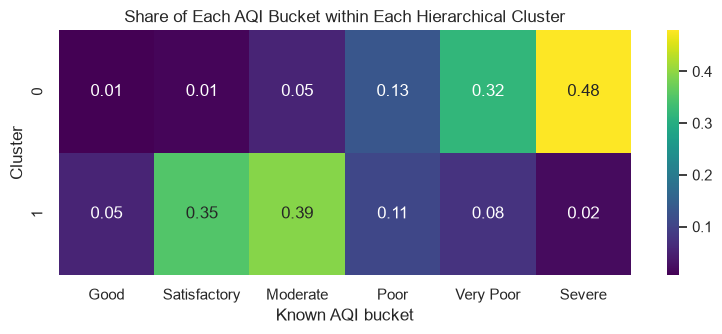

In [31]:
order = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]
valid = df_hc["AQI_Bucket"].notna().values

ct = pd.crosstab(labels_h[valid], df_hc.loc[valid, "AQI_Bucket"])
ct = ct[[c for c in order if c in ct.columns]]
ct.index.name = "Hierarchical cluster"
display(ct)

print("Adjusted Rand Index vs. AQI_Bucket:",
      round(adjusted_rand_score(df_hc.loc[valid, "AQI_Bucket"], labels_h[valid]), 3))

plt.figure(figsize=(8, 3.5))
sns.heatmap(ct.div(ct.sum(axis=1), axis=0), annot=True, fmt=".2f", cmap="viridis")
plt.title("Share of Each AQI Bucket within Each Hierarchical Cluster")
plt.xlabel("Known AQI bucket")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()

### Observation: Validation

Among the labelled rows, **Cluster 0** is dominated by **Severe (160)** and **Very Poor (106)** observations, followed by Poor (44); this supports interpreting it as the more polluted profile. **Cluster 1** contains mostly **Moderate (1,527)** and **Satisfactory (1,359)** observations, with 204 Good observations; it also includes some Poor, Very Poor and Severe days. The Adjusted Rand Index is only **0.084**, showing weak agreement with the official AQI buckets. This is not automatically a clustering failure: AQI buckets are based on the worst pollutant and fixed thresholds, whereas clustering uses all 11 pollutant features and discovers similarity without labels. The dataset also combines many cities, so city-specific patterns may influence the groups. Treat this as a post-hoc comparison, not proof that the clusters reproduce AQI categories.

## 16. Summary (Hierarchical)

- **Final model:** Agglomerative Clustering, Ward linkage, k = 2, fitted on a 5,000-row random sample (same size and seed as the K-Means diagnostic sample).
- **Linkage choice:** Ward, because it avoids the extreme one/few-point clusters produced by average, complete and single linkage, although its own cluster sizes remain imbalanced.
- **Metrics:** Ward has Silhouette = 0.596, Davies–Bouldin = 1.422 and Calinski–Harabasz = 1161.163 on the sample. In the K-Means comparison, the metrics are mixed rather than unanimously favouring one method.
- **Visualisations:** dendrogram, PCA and t-SNE for both algorithms. The first two PCA components explain 48.5% of the variance.
- **Post-hoc validation:** Cluster 0 is associated with more polluted AQI buckets, but agreement with `AQI_Bucket` is weak (ARI = 0.084).
- **Limitation:** hierarchical clustering ran on a sample because the full distance matrix is too large; results may differ slightly with another sample. The data covers multiple cities and the clusters are pollutant profiles, not official AQI categories.